In [1]:
#!/usr/bin/env python3

import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pymongo import MongoClient
import numpy as np
import warnings
import matplotlib.patches as mpatches
import textwrap

warnings.filterwarnings("ignore", category=FutureWarning, module="seaborn")

# -------------------- CONFIG --------------------
MONGO_URI = "mongodb://localhost:27017/"
DB_NAME = "validation_db"
COLLECTION_NAME = "document_validations"
OUTPUT_DIR = "./figures_tables/schema_analysis_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)
# ------------------------------------------------

In [2]:


# Connect to MongoDB
print("🔌 Connecting to MongoDB...")
client = MongoClient(MONGO_URI)
collection = client[DB_NAME][COLLECTION_NAME]

# Extract data
print("📥 Extracting schema validation data...")
cursor = collection.find({}, {
    "_id": 1,
    "validation_info.checks.schema_validation.status": 1,
    "validation_info.checks.schema_validation.metrics.validation_errors": 1,
    "validation_info.checks.text_validation.metrics.fulltext_chars": 1,
    "validation_info.checks.text_validation.metrics.abstract_chars": 1
})

records = []
for doc in cursor:
    _id = doc.get("_id")
    val_info = doc.get("validation_info", {})
    schema_check = val_info.get("checks", {}).get("schema_validation", {})
    text_metrics = val_info.get("checks", {}).get("text_validation", {}).get("metrics", {})

    errors = schema_check.get("metrics", {}).get("validation_errors", [])
    records.append({
        "_id": _id,
        "schema_status": schema_check.get("status"),
        "error_count": len(errors),
        "fulltext_chars": text_metrics.get("fulltext_chars", 0),
        "abstract_chars": text_metrics.get("abstract_chars", 0),
        "errors": errors
    })

df = pd.DataFrame(records)
print(f"✅ Loaded {len(df)} documents")

🔌 Connecting to MongoDB...
📥 Extracting schema validation data...
✅ Loaded 582683 documents


In [3]:
# Log documents with errors
error_docs = df[df["error_count"] > 0].copy()
error_docs["error_messages"] = error_docs["errors"].apply(
    lambda errs: [e.get("message", "") for e in errs if isinstance(e, dict)]
)

error_log_path = os.path.join(OUTPUT_DIR, "documents_with_errors.csv")
error_docs[["_id", "error_count", "error_messages"]].to_csv(error_log_path, index=False)

print(f"📝 Logged {len(error_docs)} documents with schema errors to: {error_log_path}")


📝 Logged 122286 documents with schema errors to: ./figures_tables/schema_analysis_output/documents_with_errors.csv


In [4]:
from pathlib import Path
import re

def safe_filename(msg):
    # Make error messages safe for filenames
    msg = msg.lower()
    msg = re.sub(r"[^a-z0-9]+", "_", msg)  # replace non-alphanum with underscore
    return msg.strip("_")[:50]  # limit length to avoid issues

error_output_dir = Path(OUTPUT_DIR) / "error_logs"
error_output_dir.mkdir(parents=True, exist_ok=True)

# Explode errors and filter valid dicts with messages
df_errors = df.explode("errors").dropna(subset=["errors"])
df_errors = df_errors[df_errors["errors"].apply(lambda e: isinstance(e, dict))]
df_errors["message"] = df_errors["errors"].apply(lambda e: e.get("message", ""))

# Group documents by error message
grouped = df_errors.groupby("message")

print("\n🗃️ Writing error logs by error type:")
for error_msg, group in grouped:
    safe_name = safe_filename(error_msg)
    out_path = error_output_dir / f"errors_{safe_name}.csv"
    
    doc_subset = group[["_id"]].drop_duplicates().copy()
    doc_subset["error_message"] = error_msg
    doc_subset.to_csv(out_path, index=False)
    
    print(f"  - {len(doc_subset)} docs ➜ {out_path.name}")



🗃️ Writing error logs by error type:
  - 39575 docs ➜ errors_abstract_embedding_is_a_required_property.csv
  - 39575 docs ➜ errors_predicted_subfield_is_a_required_property.csv
  - 82711 docs ➜ errors_is_too_short.csv


In [5]:
# ----------------------------------------------------
# Existing error messages expansion
# ----------------------------------------------------
df_errors = df.explode("errors").dropna(subset=["errors"])
df_errors = df_errors[df_errors["errors"].apply(lambda e: isinstance(e, dict))]
df_errors["message"] = df_errors["errors"].apply(lambda e: e.get("message", ""))

# ----------------------------------------------------
# Add abstract length flags
# ----------------------------------------------------
EMPTY_ABSTRACT_FLAG = df["abstract_chars"] == 0
SHORT_ABSTRACT_FLAG = (df["abstract_chars"] > 0) & (df["abstract_chars"] < 1000)

df["length_error"] = None
df.loc[EMPTY_ABSTRACT_FLAG, "length_error"] = "Abstract length = 0 chars"
df.loc[SHORT_ABSTRACT_FLAG, "length_error"] = "Abstract length between 1 and 999 chars"

# Group schema errors per doc
doc_errors = df_errors.groupby("_id")["message"].apply(set).reset_index()

# Add the abstract length flags as pseudo-errors
doc_errors["message"] = doc_errors.apply(
    lambda r: (
        r["message"] | {df.loc[df["_id"] == r["_id"], "length_error"].iloc[0]}
        if df.loc[df["_id"] == r["_id"], "length_error"].iloc[0] is not None
        else r["message"]
    ),
    axis=1
)

# Top error messages
df_errors["message"] = df_errors["errors"].apply(lambda e: e.get("message", ""))

msg_counts = df_errors["message"].value_counts().reset_index()
msg_counts.columns = ["error_message", "count"]


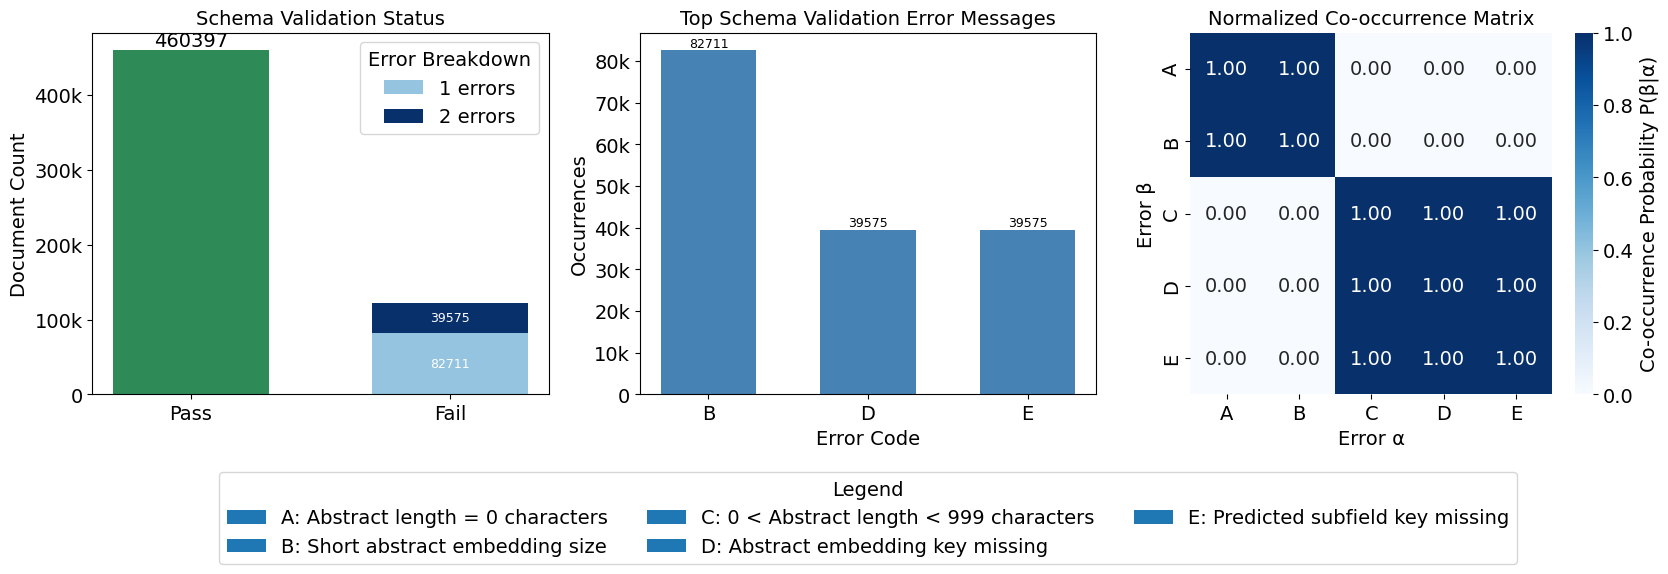

In [7]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import matplotlib.patches as mpatches
import textwrap
import matplotlib.ticker as mtick

# ----------------------------------------------------
# Prepare Pass/Fail stacked bar chart data
# ----------------------------------------------------
df_pass = df[df["schema_status"] == "pass"]
df_fail = df[df["schema_status"] == "fail"]

fail_counts_by_err = df_fail["error_count"].value_counts().sort_index()

total_pass = len(df_pass)
total_fail = len(df_fail)

# ----------------------------------------------------
# Build co-occurrence matrix from doc_errors
# ----------------------------------------------------
top_n = 10
all_errors = pd.Series([m for msgs in doc_errors["message"] for m in msgs])
top_errors = all_errors.value_counts().head(top_n).index.tolist()

binary = pd.DataFrame(0, index=doc_errors["_id"], columns=top_errors)
for _, row in doc_errors.iterrows():
    for msg in row["message"]:
        if msg in top_errors:
            binary.at[row["_id"], msg] = 1

co_matrix_count = binary.T.dot(binary)
norm_matrix = co_matrix_count.div(np.diag(co_matrix_count), axis=0).fillna(0)

# ----------------------------------------------------
# Short labels for errors
# ----------------------------------------------------
short_labels = {msg: chr(65 + i) for i, msg in enumerate(top_errors)}
label_list = [short_labels[msg] for msg in top_errors]
new_label_list = [lbl for lbl in label_list if lbl != 'E'] + ['E']

norm_matrix.index = label_list
norm_matrix.columns = label_list
norm_matrix = norm_matrix.loc[new_label_list, new_label_list]

# ----------------------------------------------------
# Prepare bar plot data
# ----------------------------------------------------
msg_counts_short = msg_counts.copy()
msg_counts_short["short_label"] = msg_counts_short["error_message"].map(short_labels)

# ----------------------------------------------------
# Custom readable names for legend
# ----------------------------------------------------
custom_legend_names = {
    "A": "Abstract length = 0 characters",
    "B": "Short abstract embedding size",
    "C": "0 < Abstract length < 999 characters",
    "D": "Abstract embedding key missing",
    "E": "Predicted subfield key missing"
}

# ----------------------------------------------------
# Formatter for thousands (10k style)
# ----------------------------------------------------
def thousands_formatter(x, pos):
    if x >= 1000:
        return f"{int(x/1000)}k"
    else:
        return str(int(x))

# --- Set global font sizes before plotting ---
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.titlesize": 16
})

# ----------------------------------------------------
# Create 2×3 layout
# ----------------------------------------------------
fig = plt.figure(figsize=(17, 6))
gs = gridspec.GridSpec(2, 3, figure=fig, height_ratios=[4, 1])

bar_width = 0.6

# --- Row 1, Col 1: Pass/Fail stacked bar ---
ax_passfail = fig.add_subplot(gs[0, 0])
categories_pf = ["Pass", "Fail"]
x_pf = np.arange(len(categories_pf))

ax_passfail.bar(x_pf[0], total_pass, color="seagreen", width=bar_width)
ax_passfail.text(x_pf[0], total_pass, str(total_pass), ha="center", va="bottom")

bottom_val = 0
colors = plt.cm.Blues(np.linspace(0.4, 1, len(fail_counts_by_err)))
for (err_count, count), color in zip(fail_counts_by_err.items(), colors):
    ax_passfail.bar(x_pf[1], count, bottom=bottom_val, color=color, width=bar_width, label=f"{err_count} errors")
    ax_passfail.text(x_pf[1], bottom_val + count / 2, str(count),
                     ha="center", va="center", color="white", fontsize=9)
    bottom_val += count

ax_passfail.set_xticks(x_pf)
ax_passfail.set_xticklabels(categories_pf)
ax_passfail.set_ylabel("Document Count")
ax_passfail.set_title("Schema Validation Status")
ax_passfail.legend(title="Error Breakdown", loc="upper right", frameon=True)
ax_passfail.yaxis.set_major_formatter(mtick.FuncFormatter(thousands_formatter))

# --- Row 1, Col 2: Top Schema Validation Errors ---
ax_bar = fig.add_subplot(gs[0, 1])
categories_err = msg_counts_short.head(20)["short_label"].tolist()
x_err = np.arange(len(categories_err))
y_err = msg_counts_short.head(20)["count"].tolist()

ax_bar.bar(x_err, y_err, color="steelblue", width=bar_width)
ax_bar.set_xticks(x_err)
ax_bar.set_xticklabels(categories_err)
ax_bar.set_title("Top Schema Validation Error Messages")
ax_bar.set_xlabel("Error Code")
ax_bar.set_ylabel("Occurrences")
ax_bar.yaxis.set_major_formatter(mtick.FuncFormatter(thousands_formatter))

for x, y in zip(x_err, y_err):
    ax_bar.text(x, y, str(int(y)), ha="center", va="bottom", fontsize=9)

# --- Row 1, Col 3: Normalized Co-occurrence Heatmap ---
ax_heatmap = fig.add_subplot(gs[0, 2])
sns.heatmap(
    norm_matrix,
    annot=True, fmt=".2f", cmap="Blues", square=True,
    cbar_kws={'label': 'Co-occurrence Probability P(β|α)'},
    ax=ax_heatmap
)
ax_heatmap.set_title("Normalized Co-occurrence Matrix")
ax_heatmap.set_xlabel("Error α")
ax_heatmap.set_ylabel("Error β")

# --- Row 2: Legend spanning all columns ---
legend_handles = []
for code in new_label_list:
    name = custom_legend_names.get(code, code)
    wrapped = "\n".join(textwrap.wrap(name, width=50))
    legend_handles.append(mpatches.Patch(label=f"{code}: {wrapped}"))

ax_legend = fig.add_subplot(gs[1, :])  # span all columns
ax_legend.axis("off")
ax_legend.legend(
    handles=legend_handles,
    loc="center", ncol=3,  # multiple columns for better fit
    title="Legend", frameon=True
)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "combined_schema_validation_2x3.png"),
            bbox_inches='tight', dpi=300)
plt.show()
